# Range Minimum Query: theoretical-optimal vs practical

Analysis of the Google Benchmark results in `run_results/results_run*.csv`
(one CSV per independent run of `bench.sh`; the median over runs is plotted, the min-max range is shaded).

| Section | Question | Prediction |
|---|---|---|
| A | Build time | naive block is the slowest build (from which n?),  Fischer-Heun's build constant |
| B | Memory | memory ordering; segment-tree padding |
| C | Input pattern | random vs ascending arrays |
| D | Query time | linear vs range length, segment tree vs the O(1) structures, constants among O(1) structures, cache effects |
| E | Break-even | build + q queries: which structure wins for which (n, q) |
| F | Fischer-Heun block size | build time and memory vs block size b |

Run the cells top to bottom. Everything is configured in the next cell.

In [1]:
from pathlib import Path
import re

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from matplotlib.colors import ListedColormap
from matplotlib.patches import Patch
from matplotlib.ticker import FixedLocator, FuncFormatter, NullLocator

# ---- configuration -------------------------------------------------------
CANDIDATE_DIRS = [Path("run_results"), Path("bench/run_results"), Path("../bench/run_results")]
FILE_GLOB = "results_run*.csv"
FIG_DIR = Path("figures")        # every figure is also saved here as PNG + PDF
TIME_COL = "cpu_time"            # or "real_time"
MAIN_PATTERN = "random"          # input pattern used for the main figures
MEM_MIN_N = 256                  # memory counters below this n read 0 or far too small: not plotted
FH_DEFAULT_B = 10                # block size Fischer-Heun picks at n = 2^20 (check against fischer_heun.cpp)

# CSV implementation name -> (legend label, colour, marker)
IMPLS = {
    "Naive_Linear": ("Naive linear", "#7f7f7f", "o"),
    "Naive_Block":  ("Naive block", "#ff7f0e", "v"),
    "Segment_Tree": ("Segment tree", "#2ca02c", "s"),
    "Sparse_Table": ("Sparse table", "#1f77b4", "^"),
    "Fischer_Heun": ("Fischer\u2013Heun", "#d62728", "D"),
}
ORDER = list(IMPLS)

pd.set_option("display.max_colwidth", None)
pd.set_option("display.width", 200)
plt.rcParams.update({
    "figure.dpi": 110, "font.size": 10,
    "axes.spines.top": False, "axes.spines.right": False,
    "figure.constrained_layout.use": True,
})
FIG_DIR.mkdir(exist_ok=True)

## 1. Load the data

Every `results_run*.csv` is read (the machine-info lines above the `name,...` header are skipped), the benchmark name is split into
family / implementation / input pattern / parameters (`n`, `q`, `b`), and all times are converted to nanoseconds
(the CSVs mix `ns`, `us` and `ms`, depending on the benchmark). The median, min and max are then taken across runs.

In [2]:
UNIT_NS = {"ns": 1.0, "us": 1e3, "ms": 1e6, "s": 1e9}
NAME_RE = re.compile(r"^BM_(?P<family>\w+?)(?:<(?P<impl>[\w:]+)>)?(?P<rest>(?:/[\w.]+(?::[\w.]+)?)*)$")


def parse_name(name):
    """'BM_Query<Sparse_Table>/short_range/n:1024' -> family, impl, pattern, {'n': '1024'}"""
    m = NAME_RE.match(name)
    if not m:
        return None
    toks = [t for t in m["rest"].split("/") if t]
    pattern = next((t for t in toks if ":" not in t), None)
    params = dict(t.split(":", 1) for t in toks if ":" in t)
    impl = (m["impl"] or "").split("::")[-1] or None
    return m["family"], impl, pattern, params


def find_files():
    for d in CANDIDATE_DIRS:
        files = sorted(d.glob(FILE_GLOB))
        if files:
            return files
    raise FileNotFoundError(f"No {FILE_GLOB} in any of {[str(d) for d in CANDIDATE_DIRS]}")


def read_run(path, run_id):
    lines = path.read_text(encoding="utf-8-sig").splitlines()
    header = next(i for i, l in enumerate(lines) if l.startswith("name,"))
    d = pd.read_csv(path, skiprows=header, encoding="utf-8-sig")
    d["run"] = run_id
    return d, [l.strip() for l in lines[:header]]


files = find_files()
runs, preambles = zip(*(read_run(p, i + 1) for i, p in enumerate(files)))
raw = pd.concat(runs, ignore_index=True)

if "error_occurred" in raw:
    raw = raw[~raw["error_occurred"].astype(str).str.lower().eq("true")]

parsed = raw["name"].map(parse_name)
bad = parsed.isna()
if bad.any():
    print(f"[warn] ignoring {bad.sum()} rows with unrecognised names, e.g. {raw.loc[bad, 'name'].iloc[0]!r}")
raw, parsed = raw[~bad].copy(), parsed[~bad]
parts = pd.DataFrame(parsed.tolist(), columns=["family", "impl", "pattern", "params"], index=raw.index)
raw = pd.concat([raw, parts.drop(columns="params")], axis=1)
for k in ("n", "q", "b"):
    raw[k] = [float(p[k]) if k in p else np.nan for p in parts["params"]]

raw["t_ns"] = raw[TIME_COL] * raw["time_unit"].map(UNIT_NS)
raw["bytes_"] = raw["bytes"] if "bytes" in raw else np.nan
raw["bpe"] = raw["bytes/elem"] if "bytes/elem" in raw else np.nan

KEYS = ["family", "impl", "pattern", "n", "q", "b"]
res = (raw.groupby(KEYS, dropna=False)
          .agg(t=("t_ns", "median"), lo=("t_ns", "min"), hi=("t_ns", "max"), runs=("t_ns", "size"),
               bpe=("bpe", "median"), bytes_=("bytes_", "median"))
          .reset_index())
res["t_per_elem"] = res["t"] / res["n"]
HAS_MEM = bool(res["bpe"].fillna(0).max() > 0)

# ---- machine info (for the methodology section) -----------------------------
print(f"{len(files)} run files: {[f.name for f in files]}")
print("\n".join(preambles[0]))
CACHES = {}
for key, pat in {"L1d": r"L1 Data (\d+) KiB", "L2": r"L2 Unified (\d+) KiB", "L3": r"L3 Unified (\d+) KiB"}.items():
    m = re.search(pat, "\n".join(preambles[0]))
    if m:
        CACHES[key] = int(m.group(1)) * 1024
print("\nmemory counters present:", HAS_MEM)

5 run files: ['results_run1.csv', 'results_run2.csv', 'results_run3.csv', 'results_run4.csv', 'results_run5.csv']
Running ./build/range_minimum_query_bench
Run on (8 X 4694.99 MHz CPU s)
CPU Caches:
L1 Data 32 KiB (x8)
L1 Instruction 32 KiB (x8)
L2 Unified 256 KiB (x8)
L3 Unified 12288 KiB (x1)
Load Average: 0.11, 0.25, 0.40

memory counters present: True


In [3]:
# ---- inventory: what was measured -------------------------------------------
inv = (res.groupby(["family", "pattern"], dropna=False)
          .agg(impls=("impl", lambda s: ", ".join(sorted(s.dropna().unique()))),
               n_min=("n", "min"), n_max=("n", "max"), q_values=("q", lambda s: sorted(s.dropna().astype(int).unique())),
               points=("t", "size"), runs=("runs", "max")))
display(inv)

impls   n_min       n_max                  q_values  points  runs
family                   pattern                                                                                                                                                 
Construct                ascending                Fischer_Heun, Naive_Block, Naive_Linear, Segment_Tree, Sparse_Table    16.0  16777216.0                        []      50     5
                         random                   Fischer_Heun, Naive_Block, Naive_Linear, Segment_Tree, Sparse_Table    16.0  16777216.0                        []      50     5
                         random_non_power_of_two                                                         Segment_Tree  1024.0   6291456.0                        []      21     5
FH_Different_Block_Sizes NaN                                                                                              NaN         NaN                        []      15     5
Multiple_Queries         NaN                      Fischer_Heun, Naive_Block, Naive_Linear, Segment_Tree, Sparse_Table  1024.0   4194304.0  [1, 100, 10000, 1000000]      72     5
Query                    long_range               Fischer_Heun, Naive_Block, Naive_Linear, Segment_Tree, Sparse_Table    16.0  16777216.0                        []      50     5
                         random                   Fischer_Heun, Naive_Block, Naive_Linear, Segment_Tree, Sparse_Table    16.0  16777216.0                        []      50     5
                         random_non_power_of_two                                                         Segment_Tree  1024.0   6291456.0                        []      21     5
                         short_range              Fischer_Heun, Naive_Block, Naive_Linear, Segment_Tree, Sparse_Table    16.0  16777216.0                        []      50     5
                         single                   Fischer_Heun, Naive_Block, Naive_Linear, Segment_Tree, Sparse_Table    16.0  16777216.0                        []      50     5

In [4]:
# ---- helpers ---------------------------------------------------------------------
def sub(family, pattern=None):
    d = res[res["family"] == family]
    return d if pattern is None else d[d["pattern"] == pattern]


def wide(d, col="t", index="n"):
    """One row per n (or q/b), one column per implementation."""
    return d.pivot(index=index, columns="impl", values=col).sort_index()


def style(impl):
    return IMPLS.get(impl, (impl, "black", "x"))


def pow2_fmt(v, _):
    k = np.log2(v)
    return f"$2^{{{int(round(k))}}}$" if abs(k - round(k)) < 1e-9 else ""


def times_fmt(v, _):
    return f"{v:g}\u00d7"


def human_bytes(v, _=None):
    for unit in ("B", "KiB", "MiB", "GiB", "TiB"):
        if v < 1024:
            return f"{v:g} {unit}"
        v /= 1024
    return f"{v:g} PiB"


def n_axis(ax, ns, ylabel, logy=True, title=None):
    ks = range(int(np.floor(np.log2(np.min(ns)))), int(np.ceil(np.log2(np.max(ns)))) + 1)
    ax.set_xscale("log", base=2)
    if logy:
        ax.set_yscale("log")
    ax.xaxis.set_major_locator(FixedLocator([2 ** k for k in ks if (k - ks[0]) % 2 == 0]))
    ax.xaxis.set_major_formatter(FuncFormatter(pow2_fmt))
    ax.xaxis.set_minor_locator(NullLocator())
    ax.set_xlabel("array size n")
    ax.set_ylabel(ylabel)
    ax.grid(True, which="major", alpha=0.3)
    if title:
        ax.set_title(title, fontsize=11)


def times_axis(ax):
    fmt = FuncFormatter(times_fmt)
    ax.yaxis.set_major_formatter(fmt)
    ax.yaxis.set_minor_formatter(fmt)


def draw(ax, d, impl, col="t", scale=1.0, band=True, **kw):
    x = d[d["impl"] == impl].sort_values("n")
    if x.empty:
        return
    label, colour, marker = style(impl)
    kw.setdefault("label", label)
    ax.plot(x["n"], x[col] * scale, marker=marker, ms=4.5, lw=1.6, color=colour, **kw)
    if band and col == "t":
        ax.fill_between(x["n"], x["lo"] * scale, x["hi"] * scale, color=colour, alpha=0.2, lw=0)


def fmt_time(ns):
    for unit, div in (("s", 1e9), ("ms", 1e6), ("µs", 1e3)):
        if ns >= div:
            return f"{ns / div:.3g} {unit}"
    return f"{ns:.3g} ns"


def save(fig, name):
    for ext in ("png", "pdf"):
        fig.savefig(FIG_DIR / f"{name}.{ext}", dpi=200)
    plt.show()


def crossings(w, a, b):
    """n-intervals where a and b swap order in a wide table (who becomes faster after)."""
    if a not in w or b not in w:
        return []
    d = (w[a] - w[b]).dropna()
    s = np.sign(d.to_numpy())
    out = []
    for i in range(1, len(s)):
        if s[i] != 0 and s[i] != s[i - 1]:
            out.append((int(d.index[i - 1]), int(d.index[i]), a if s[i] < 0 else b))
    return out


def report_crossings(w, pairs, label):
    for a, b in pairs:
        cs = crossings(w, a, b)
        if not cs:
            who = None
            both = w[[a, b]].dropna() if a in w and b in w else None
            if both is not None and len(both):
                who = a if (both[a] < both[b]).all() else b if (both[b] < both[a]).all() else None
            print(f"  [{label}] {a} vs {b}: no crossover in the measured range" + (f" ({who} always faster)" if who else ""))
        for lo, hi, winner in cs:
            print(f"  [{label}] between n={lo:,} and n={hi:,}: {winner} becomes the faster one ({a} vs {b})")

## A. Build time

**#5 Naive block is the slowest build.** Stated as a regime: from which n does it become (and stay) the slowest?
The dotted line is an n² guide through naive block's last point.

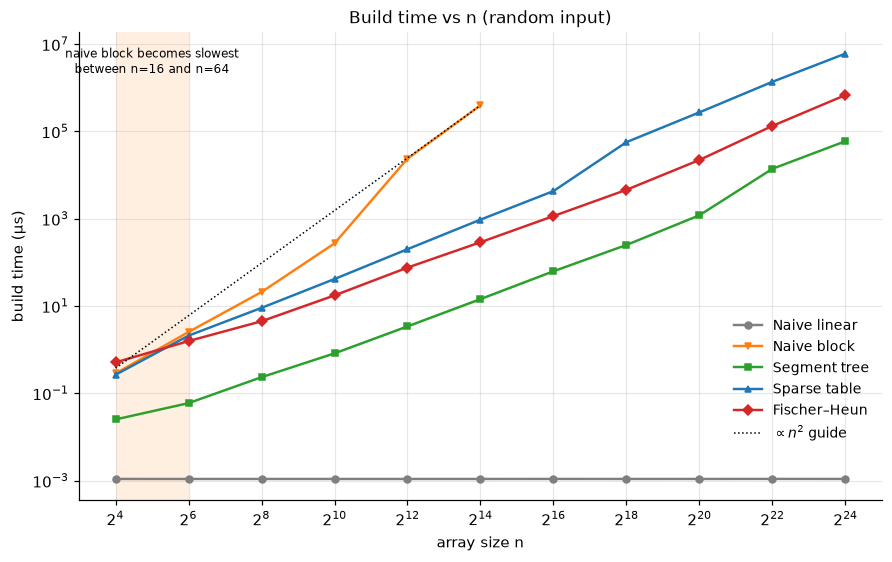

Slowest / fastest build per n (random input, among the implementations measured at that n):
  n=        16  slowest: Fischer_Heun  fastest: Naive_Linear 
  n=        64  slowest: Naive_Block   fastest: Naive_Linear 
  n=       256  slowest: Naive_Block   fastest: Naive_Linear 
  n=     1,024  slowest: Naive_Block   fastest: Naive_Linear 
  n=     4,096  slowest: Naive_Block   fastest: Naive_Linear 
  n=    16,384  slowest: Naive_Block   fastest: Naive_Linear 
  n=    65,536  slowest: Sparse_Table  fastest: Naive_Linear 
  n=   262,144  slowest: Sparse_Table  fastest: Naive_Linear 
  n= 1,048,576  slowest: Sparse_Table  fastest: Naive_Linear 
  n= 4,194,304  slowest: Sparse_Table  fastest: Naive_Linear 
  n=16,777,216  slowest: Sparse_Table  fastest: Naive_Linear 

#5: naive block becomes the slowest build between n=16 and n=64


In [5]:
d = sub("Construct", MAIN_PATTERN)
w = wide(d)                                   # nanoseconds

fig, ax = plt.subplots(figsize=(8, 5))
for impl in ORDER:
    draw(ax, d, impl, scale=1e-3)
if "Naive_Block" in w:
    nb = w["Naive_Block"].dropna()
    xs = nb.index.to_numpy(float)
    ax.plot(xs, nb.iloc[-1] * 1e-3 * (xs / xs[-1]) ** 2, "k:", lw=1, label=r"$\propto n^2$ guide")
n_axis(ax, d["n"], "build time (\u00b5s)", title=f"Build time vs n ({MAIN_PATTERN} input)")


def block_crossover(w, block="Naive_Block"):
    if block not in w:
        return None
    ns = w[block].dropna().index
    flags = (w.loc[ns].idxmax(axis=1) == block).to_numpy()
    for i in range(len(ns)):
        if flags[i:].all():
            return (int(ns[i - 1]) if i else None), int(ns[i])
    return None


cross = block_crossover(w)
if cross:
    prev, n_star = cross
    if prev:
        ax.axvspan(prev, n_star, color=IMPLS["Naive_Block"][1], alpha=0.12, lw=0)
        msg, x = f"naive block becomes slowest\nbetween n={prev:,} and n={n_star:,}", np.sqrt(prev * n_star)
    else:
        msg, x = f"naive block slowest at every\nmeasured n (from n={n_star:,})", n_star
    ax.text(x, 0.97, msg, transform=ax.get_xaxis_transform(), ha="center", va="top", fontsize=8)
ax.legend(frameon=False, fontsize=9, loc="lower right", bbox_to_anchor=(1.0, 0.1))
save(fig, "A1_build_time")

print(f"Slowest / fastest build per n ({MAIN_PATTERN} input, among the implementations measured at that n):")
for n, row in w.iterrows():
    print(f"  n={int(n):>10,}  slowest: {row.idxmax():<13} fastest: {row.idxmin():<13}")
print("\n#5:", f"naive block becomes the slowest build between n={cross[0]:,} and n={cross[1]:,}" if cross and cross[0]
      else f"naive block is the slowest build from n={cross[1]:,}" if cross else "naive block never settles as the slowest build")

**#11 Fischer-Heun's build constant.** Time per element: a flat line means a linear-time build, a rising line means super-linear
behaviour (more work per element, or cache effects). Then the ratios of Fischer-Heun's build time to the segment tree's and the sparse table's.

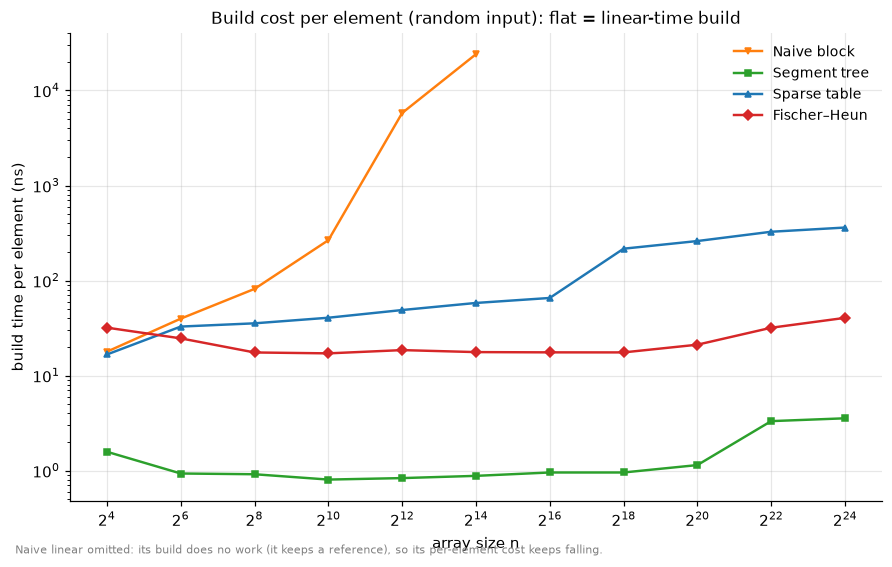

In [6]:
d = sub("Construct", MAIN_PATTERN)
fig, ax = plt.subplots(figsize=(8, 5))
for impl in ORDER:
    if impl == "Naive_Linear":       # constant-time build (~1 ns): per-element cost falls off the chart
        continue
    draw(ax, d, impl, col="t_per_elem")
n_axis(ax, d["n"], "build time per element (ns)",
       title=f"Build cost per element ({MAIN_PATTERN} input): flat = linear-time build")
ax.legend(frameon=False, fontsize=9)
fig.text(0.01, 0.005, "Naive linear omitted: its build does no work (it keeps a reference), so its per-element cost keeps falling.",
         fontsize=7, color="gray")
save(fig, "A2_build_per_element")

Fischer-Heun / Segment_Tree: min 9.61x (n=4,194,304), max 26.43x (n=64), at the largest n 11.40x
Fischer-Heun / Sparse_Table: min 0.08x (n=262,144), max 1.92x (n=16), at the largest n 0.11x


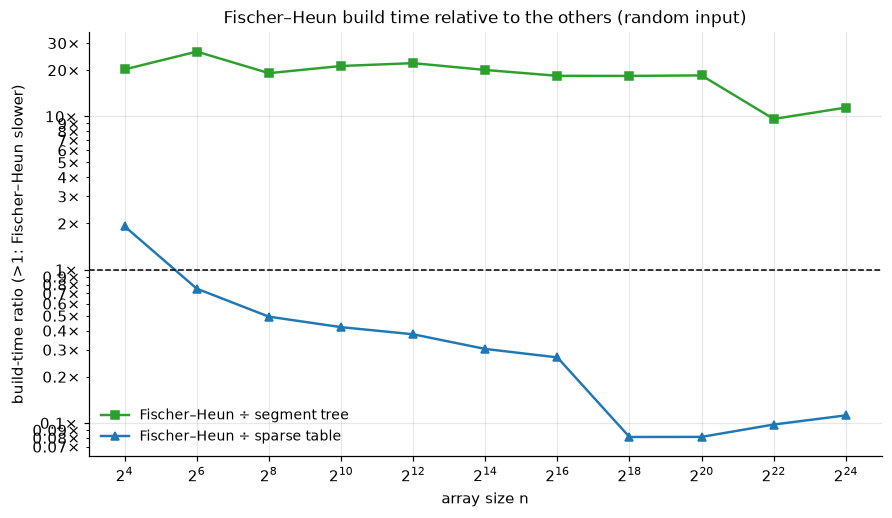

In [7]:
w = wide(sub("Construct", MAIN_PATTERN))
fig, ax = plt.subplots(figsize=(8, 4.6))
for den in ("Segment_Tree", "Sparse_Table"):
    if "Fischer_Heun" in w and den in w:
        r = (w["Fischer_Heun"] / w[den]).dropna()
        ax.plot(r.index, r, marker=style(den)[2], ms=5, lw=1.6, color=style(den)[1],
                label=f"Fischer\u2013Heun \u00f7 {style(den)[0].lower()}")
        print(f"Fischer-Heun / {den}: min {r.min():.2f}x (n={int(r.idxmin()):,}), max {r.max():.2f}x (n={int(r.idxmax()):,}), at the largest n {r.iloc[-1]:.2f}x")
ax.axhline(1, color="k", ls="--", lw=1)
n_axis(ax, w.index, "build-time ratio (>1: Fischer\u2013Heun slower)",
       title=f"Fischer\u2013Heun build time relative to the others ({MAIN_PATTERN} input)")
times_axis(ax)
ax.legend(frameon=False, fontsize=9)
save(fig, "A3_build_ratios")

## B. Memory

Counters come from `mallinfo2()`, so they include allocator overhead (per-row `vector` headers, malloc chunk padding), and they only exist in
glibc builds. Points with n < `MEM_MIN_N` are left out because the counter reads 0 or far too little for small allocations.
Naive linear stores a reference to the caller's array, so it reads 0 and cannot be drawn on a log axis.

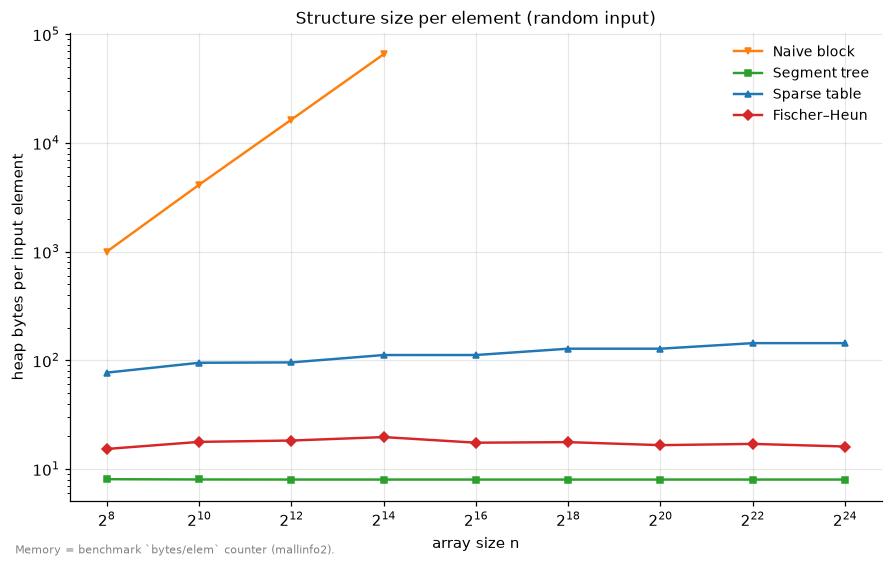

Memory ordering, largest to smallest (bytes/element):
  n=       256  Naive_Block > Sparse_Table > Fischer_Heun > Segment_Tree
  n=     1,024  Naive_Block > Sparse_Table > Fischer_Heun > Segment_Tree
  n=     4,096  Naive_Block > Sparse_Table > Fischer_Heun > Segment_Tree
  n=    16,384  Naive_Block > Sparse_Table > Fischer_Heun > Segment_Tree
  n=    65,536  Sparse_Table > Fischer_Heun > Segment_Tree
  n=   262,144  Sparse_Table > Fischer_Heun > Segment_Tree
  n= 1,048,576  Sparse_Table > Fischer_Heun > Segment_Tree
  n= 4,194,304  Sparse_Table > Fischer_Heun > Segment_Tree
  n=16,777,216  Sparse_Table > Fischer_Heun > Segment_Tree


In [8]:
if not HAS_MEM:
    print("No memory counters in this data: skipping section B.")
else:
    d = sub("Construct", MAIN_PATTERN)
    d = d[(d["n"] >= MEM_MIN_N) & (d["bpe"] > 0)]
    fig, ax = plt.subplots(figsize=(8, 5))
    for impl in ORDER:
        draw(ax, d, impl, col="bpe")
    n_axis(ax, d["n"], "heap bytes per input element", title=f"Structure size per element ({MAIN_PATTERN} input)")
    ax.legend(frameon=False, fontsize=9)
    fig.text(0.01, 0.005, "Memory = benchmark `bytes/elem` counter (mallinfo2).", fontsize=7, color="gray")
    save(fig, "B1_memory")

    wb = wide(d, "bpe")
    print("Memory ordering, largest to smallest (bytes/element):")
    for n, row in wb.iterrows():
        print(f"  n={int(n):>10,}  " + " > ".join(row.dropna().sort_values(ascending=False).index))

**Segment-tree padding.** The segment tree pads to the next power of two. `n = 2^k` is the best case, `n = 2^k + 1` the worst case
(the padded size doubles), and `n = 1.5 \u00d7 2^k` sits in between.

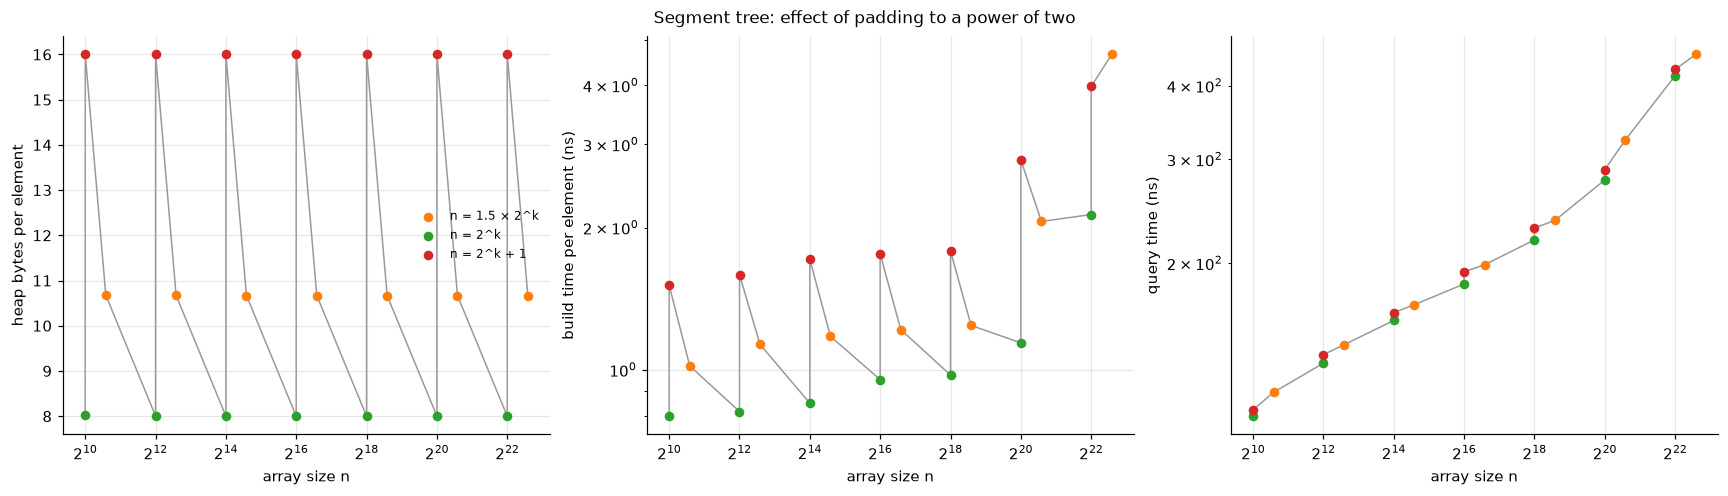

In [9]:
bp, qp = sub("Construct", "random_non_power_of_two"), sub("Query", "random_non_power_of_two")
if bp.empty:
    print("No random_non_power_of_two data.")
else:
    def kind(n):
        n = int(n)
        if n & (n - 1) == 0:
            return "n = 2^k"
        if (n - 1) & (n - 2) == 0:
            return "n = 2^k + 1"
        return "n = 1.5 \u00d7 2^k"
    colours = {"n = 2^k": "#2ca02c", "n = 2^k + 1": "#d62728", "n = 1.5 \u00d7 2^k": "#ff7f0e"}

    panels = [(bp, "bpe", 1.0, "heap bytes per element", HAS_MEM),
              (bp, "t_per_elem", 1.0, "build time per element (ns)", True),
              (qp, "t", 1.0, "query time (ns)", True)]
    panels = [p for p in panels if p[4]]
    fig, axes = plt.subplots(1, len(panels), figsize=(5.2 * len(panels), 4.4), squeeze=False)
    for ax, (d, col, sc, ylab, _) in zip(axes[0], panels):
        d = d.sort_values("n")
        if col == "bpe":
            d = d[d["n"] >= MEM_MIN_N]
        ax.plot(d["n"], d[col] * sc, color="#999999", lw=1, zorder=1)
        for k, g in d.groupby(d["n"].map(kind)):
            ax.scatter(g["n"], g[col] * sc, color=colours[k], s=28, label=k, zorder=2)
        n_axis(ax, d["n"], ylab, logy=(col != "bpe"))
    axes[0][0].legend(frameon=False, fontsize=8)
    fig.suptitle("Segment tree: effect of padding to a power of two", fontsize=11)
    save(fig, "B2_segment_tree_padding")

## C. Input-pattern sensitivity

Random vs ascending arrays. Only Fischer-Heun should care (its in-block tables depend on how many different Cartesian-tree shapes the array contains).

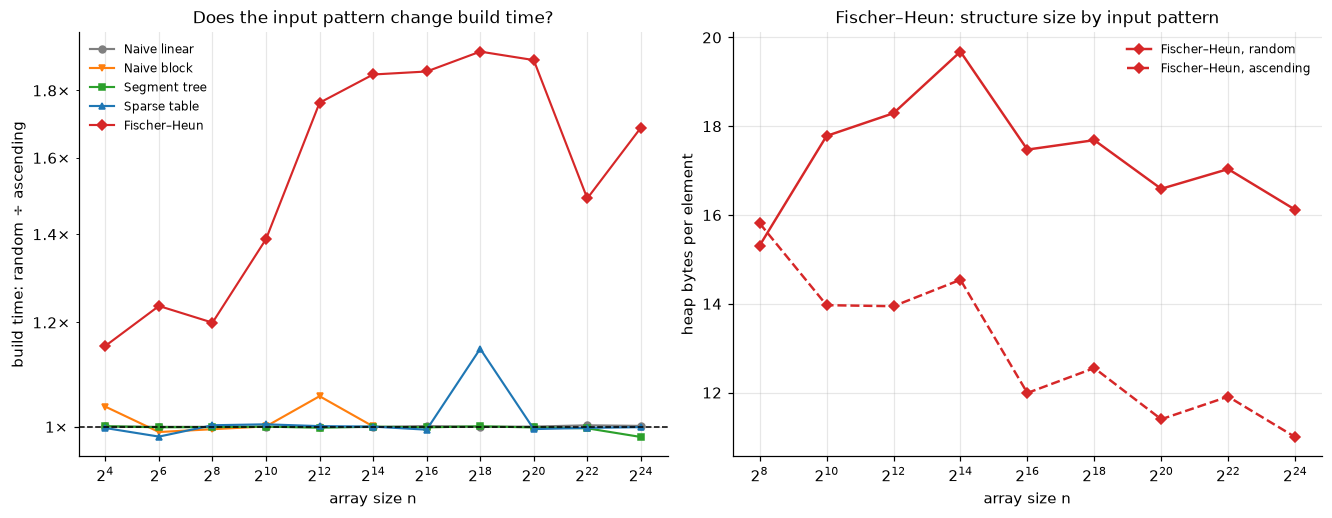

In [10]:
wa, wb_ = wide(sub("Construct", "random")), wide(sub("Construct", "ascending"))
two = HAS_MEM
fig, axes = plt.subplots(1, 2 if two else 1, figsize=(12 if two else 7, 4.6), squeeze=False)
ax = axes[0, 0]
for impl in ORDER:
    if impl in wa and impl in wb_:
        r = (wa[impl] / wb_[impl]).dropna()
        ax.plot(r.index, r, marker=style(impl)[2], ms=4.5, lw=1.4, color=style(impl)[1], label=style(impl)[0])
ax.axhline(1, color="k", ls="--", lw=1)
n_axis(ax, wa.index, "build time: random \u00f7 ascending", title="Does the input pattern change build time?")
times_axis(ax)
ax.legend(frameon=False, fontsize=8)
if two:
    ax = axes[0, 1]
    for pat, ls in (("random", "-"), ("ascending", "--")):
        d = sub("Construct", pat)
        d = d[(d["n"] >= MEM_MIN_N) & (d["bpe"] > 0)]
        draw(ax, d, "Fischer_Heun", col="bpe", label=f"Fischer\u2013Heun, {pat}", ls=ls)
    n_axis(ax, sub("Construct", "random")["n"], "heap bytes per element", logy=False,
           title="Fischer\u2013Heun: structure size by input pattern")
    ax.legend(frameon=False, fontsize=8)
save(fig, "C1_pattern_sensitivity")

## D. Query time

Four query workloads (batches of 65,536 pre-generated ranges, cycled through):

| Pattern | Range lengths |
|---|---|
| `random` | two random endpoints (average length about n/3) |
| `short_range` | 1 to 8 elements |
| `long_range` | at least n/2 |
| `single` | one element, `{i, i}` |

**#3** Linear is the slowest query only beyond some range length. **#10/#12** The segment tree sits between the sparse table and Fischer-Heun.
**#13/#6** Constant factors decide among the O(1) structures.

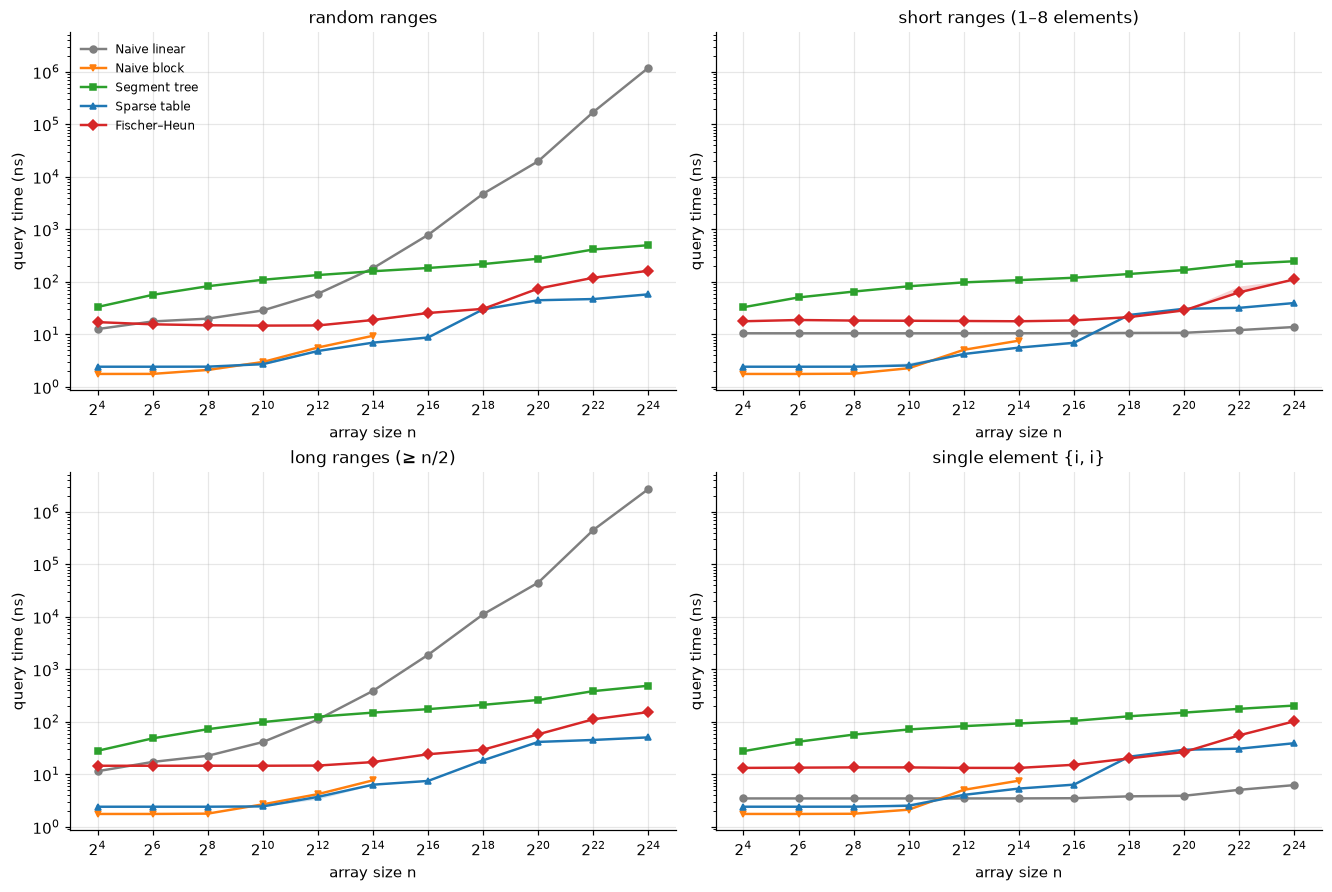

Fastest query per n:

  random: 2^4:Naive block, 2^6:Naive block, 2^8:Naive block, 2^10:Sparse table, 2^12:Sparse table, 2^14:Sparse table, 2^16:Sparse table, 2^18:Sparse table, 2^20:Sparse table, 2^22:Sparse table, 2^24:Sparse table

  short_range: 2^4:Naive block, 2^6:Naive block, 2^8:Naive block, 2^10:Naive block, 2^12:Sparse table, 2^14:Sparse table, 2^16:Sparse table, 2^18:Naive linear, 2^20:Naive linear, 2^22:Naive linear, 2^24:Naive linear

  long_range: 2^4:Naive block, 2^6:Naive block, 2^8:Naive block, 2^10:Sparse table, 2^12:Sparse table, 2^14:Sparse table, 2^16:Sparse table, 2^18:Sparse table, 2^20:Sparse table, 2^22:Sparse table, 2^24:Sparse table

  single: 2^4:Naive block, 2^6:Naive block, 2^8:Naive block, 2^10:Naive block, 2^12:Naive linear, 2^14:Naive linear, 2^16:Naive linear, 2^18:Naive linear, 2^20:Naive linear, 2^22:Naive linear, 2^24:Naive linear


In [11]:
patterns = ["random", "short_range", "long_range", "single"]
titles = {"random": "random ranges", "short_range": "short ranges (1\u20138 elements)",
          "long_range": "long ranges (\u2265 n/2)", "single": "single element {i, i}"}
fig, axes = plt.subplots(2, 2, figsize=(12, 8), sharey=True)
for ax, pat in zip(axes.flat, patterns):
    d = sub("Query", pat)
    for impl in ORDER:
        draw(ax, d, impl)
    n_axis(ax, d["n"], "query time (ns)", title=titles[pat])
axes[0, 0].legend(frameon=False, fontsize=8)
save(fig, "D1_query_time_by_pattern")

print("Fastest query per n:")
for pat in patterns:
    w = wide(sub("Query", pat))
    print(f"\n  {pat}: " + ", ".join(f"2^{int(np.log2(n))}:{style(row.idxmin())[0]}" for n, row in w.iterrows()))

In [12]:
print("Crossovers (median over runs):")
for pat in patterns:
    w = wide(sub("Query", pat))
    report_crossings(w, [("Naive_Linear", "Sparse_Table"), ("Naive_Block", "Sparse_Table"),
                         ("Segment_Tree", "Fischer_Heun"), ("Fischer_Heun", "Naive_Block")], pat)
    print()

Crossovers (median over runs):
  [random] Naive_Linear vs Sparse_Table: no crossover in the measured range (Sparse_Table always faster)
  [random] between n=256 and n=1,024: Sparse_Table becomes the faster one (Naive_Block vs Sparse_Table)
  [random] Segment_Tree vs Fischer_Heun: no crossover in the measured range (Fischer_Heun always faster)
  [random] Fischer_Heun vs Naive_Block: no crossover in the measured range (Naive_Block always faster)

  [short_range] between n=65,536 and n=262,144: Naive_Linear becomes the faster one (Naive_Linear vs Sparse_Table)
  [short_range] between n=1,024 and n=4,096: Sparse_Table becomes the faster one (Naive_Block vs Sparse_Table)
  [short_range] Segment_Tree vs Fischer_Heun: no crossover in the measured range (Fischer_Heun always faster)
  [short_range] Fischer_Heun vs Naive_Block: no crossover in the measured range (Naive_Block always faster)

  [long_range] Naive_Linear vs Sparse_Table: no crossover in the measured range (Sparse_Table always faste

**Cache effects.** The same random-query timings plotted against the structure's size in bytes, with the L1d / L2 / L3 sizes of the benchmark machine.
Size = heap bytes measured at construction (naive linear: the array it reads, 4 bytes per element). Points with n < `MEM_MIN_N` are left out.

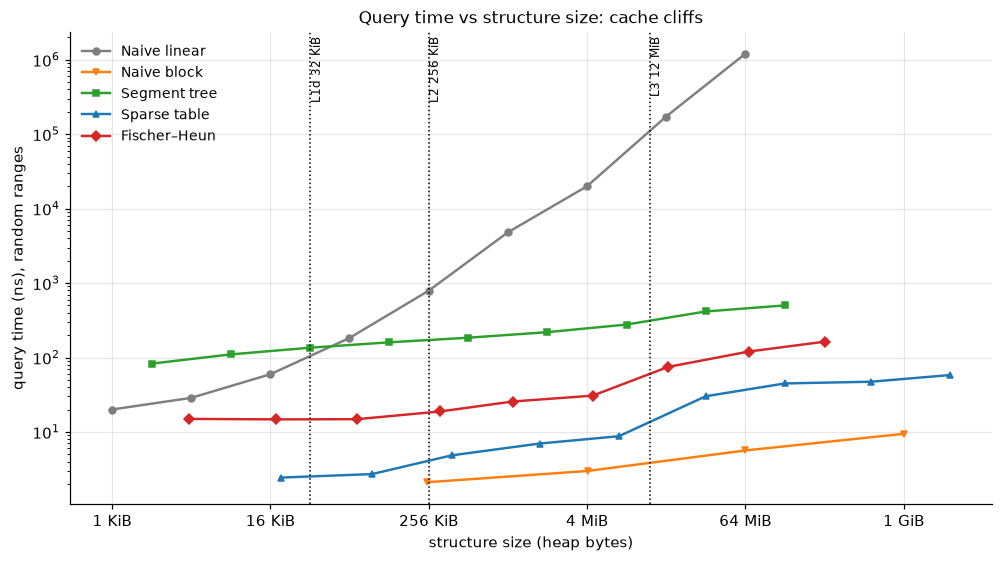

In [13]:
if not HAS_MEM:
    print("No memory counters: skipping the cache figure.")
else:
    mem = sub("Construct", MAIN_PATTERN)[["impl", "n", "bytes_"]].rename(columns={"bytes_": "ws"})
    d = sub("Query", MAIN_PATTERN).merge(mem, on=["impl", "n"], how="inner")
    d.loc[d["impl"] == "Naive_Linear", "ws"] = 4 * d["n"]
    d = d[(d["n"] >= MEM_MIN_N) & (d["ws"] > 0)]

    fig, ax = plt.subplots(figsize=(9, 5))
    for impl in ORDER:
        x = d[d["impl"] == impl].sort_values("ws")
        if x.empty:
            continue
        ax.plot(x["ws"], x["t"], marker=style(impl)[2], ms=4.5, lw=1.6, color=style(impl)[1], label=style(impl)[0])
    for name, size in CACHES.items():
        ax.axvline(size, color="k", ls=":", lw=1)
        ax.text(size, 0.99, f" {name} {human_bytes(size)}", transform=ax.get_xaxis_transform(), fontsize=8, rotation=90, va="top", ha="left")
    ax.set_xscale("log", base=2)
    ax.set_yscale("log")
    ax.xaxis.set_major_locator(FixedLocator([2 ** k for k in range(10, 34, 4)]))
    ax.xaxis.set_major_formatter(FuncFormatter(human_bytes))
    ax.xaxis.set_minor_locator(NullLocator())
    ax.set_xlabel("structure size (heap bytes)")
    ax.set_ylabel("query time (ns), random ranges")
    ax.set_title("Query time vs structure size: cache cliffs", fontsize=11)
    ax.grid(True, which="major", alpha=0.3)
    ax.legend(frameon=False, fontsize=9, loc="upper left")
    save(fig, "D2_cache_cliffs")

**Ratios among the structures with fast queries.** Values above 1\u00d7 mean the numerator is slower.

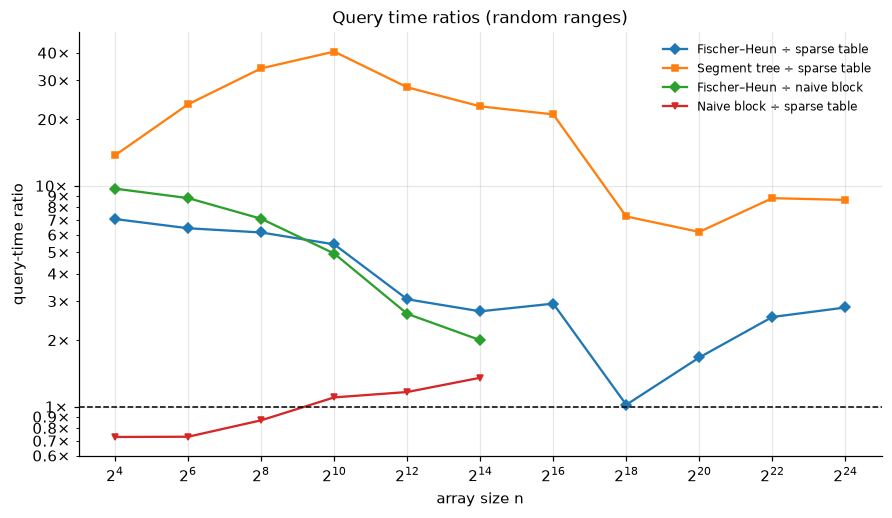

In [14]:
w = wide(sub("Query", MAIN_PATTERN))
fig, ax = plt.subplots(figsize=(8, 4.6))
pairs = [("Fischer_Heun", "Sparse_Table"), ("Segment_Tree", "Sparse_Table"), ("Fischer_Heun", "Naive_Block"), ("Naive_Block", "Sparse_Table")]
for a, b in pairs:
    if a in w and b in w:
        r = (w[a] / w[b]).dropna()
        ax.plot(r.index, r, marker=style(a)[2], ms=4.5, lw=1.5, label=f"{style(a)[0]} \u00f7 {style(b)[0].lower()}")
ax.axhline(1, color="k", ls="--", lw=1)
n_axis(ax, w.index, "query-time ratio", title=f"Query time ratios ({MAIN_PATTERN} ranges)")
times_axis(ax)
ax.legend(frameon=False, fontsize=8)
save(fig, "D3_query_ratios")

## E. Break-even: build once, then answer q queries

`BM_Multiple_Queries` times one construction plus q random queries (total per iteration, in the benchmark's own milliseconds).
Naive block only exists for n \u2264 2^14.

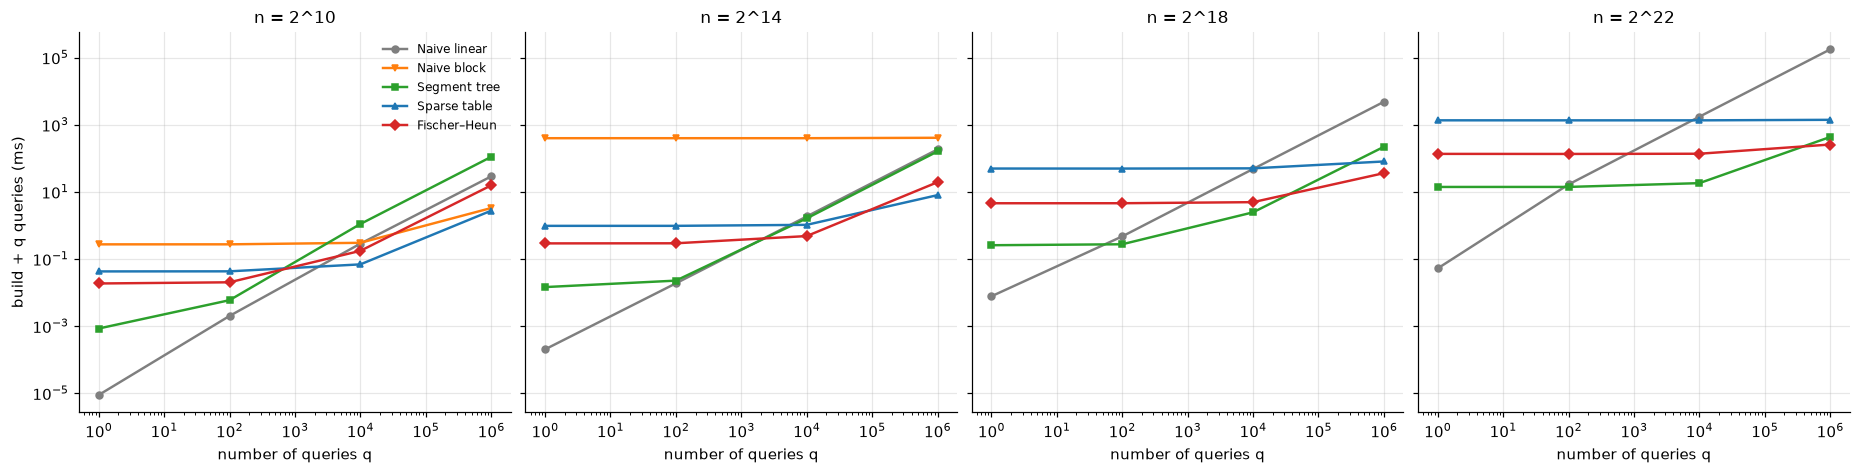

In [15]:
mq = sub("Multiple_Queries")
if mq.empty:
    print("No Multiple_Queries data.")
else:
    ns_ = sorted(mq["n"].unique())
    fig, axes = plt.subplots(1, len(ns_), figsize=(4.2 * len(ns_), 4.2), sharey=True, squeeze=False)
    for ax, n in zip(axes[0], ns_):
        dd = mq[mq["n"] == n]
        for impl in ORDER:
            x = dd[dd["impl"] == impl].sort_values("q")
            if x.empty:
                continue
            ax.plot(x["q"], x["t"] * 1e-6, marker=style(impl)[2], ms=4.5, lw=1.6, color=style(impl)[1], label=style(impl)[0])
        ax.set_xscale("log")
        ax.set_yscale("log")
        ax.set_xlabel("number of queries q")
        ax.set_title(f"n = 2^{int(np.log2(n))}", fontsize=11)
        ax.grid(True, which="major", alpha=0.3)
    axes[0][0].set_ylabel("build + q queries (ms)")
    axes[0][0].legend(frameon=False, fontsize=8)
    save(fig, "E1_break_even")

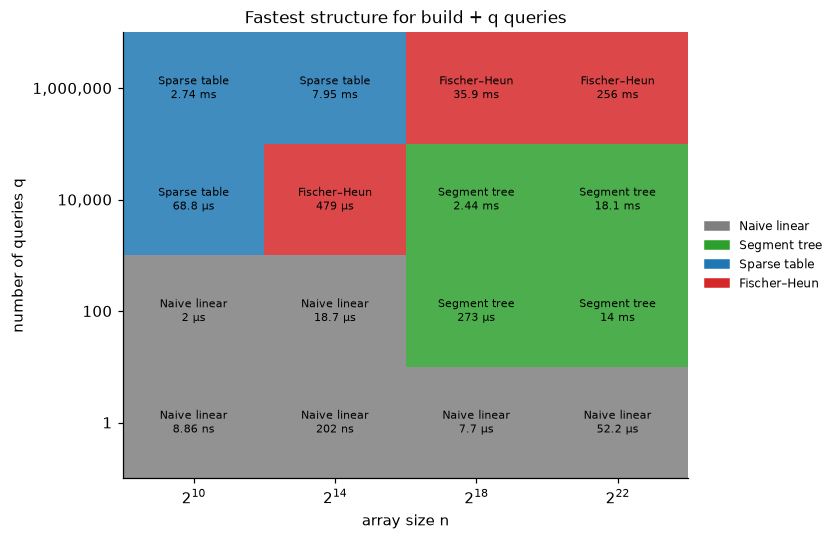

In [16]:
if not mq.empty:
    qs_ = sorted(mq["q"].unique())
    W, T = np.full((len(qs_), len(ns_)), -1), np.full((len(qs_), len(ns_)), np.nan)
    for i, q in enumerate(qs_):
        for j, n in enumerate(ns_):
            cell = mq[(mq["n"] == n) & (mq["q"] == q)].set_index("impl")["t"].dropna()
            if len(cell):
                W[i, j], T[i, j] = ORDER.index(cell.idxmin()), cell.min()

    fig, ax = plt.subplots(figsize=(7.5, 4.8))
    ax.imshow(W, cmap=ListedColormap([IMPLS[i][1] for i in ORDER]), vmin=-0.5, vmax=len(ORDER) - 0.5,
              origin="lower", aspect="auto", alpha=0.85)
    for i in range(len(qs_)):
        for j in range(len(ns_)):
            if W[i, j] >= 0:
                ax.text(j, i, f"{style(ORDER[W[i, j]])[0]}\n{fmt_time(T[i, j])}", ha="center", va="center", fontsize=7.5)
    ax.set_xticks(range(len(ns_)), [f"$2^{{{int(np.log2(n))}}}$" for n in ns_])
    ax.set_yticks(range(len(qs_)), [f"{int(q):,}" for q in qs_])
    ax.set_xlabel("array size n")
    ax.set_ylabel("number of queries q")
    ax.set_title("Fastest structure for build + q queries", fontsize=11)
    used = sorted({int(w_) for w_ in W.flat if w_ >= 0})
    ax.legend(handles=[Patch(color=IMPLS[ORDER[u]][1], label=style(ORDER[u])[0]) for u in used],
              frameon=False, fontsize=8, loc="center left", bbox_to_anchor=(1.01, 0.5))
    save(fig, "E2_winner_map")

## F. Fischer-Heun block size

`BM_FH_Different_Block_Sizes` builds Fischer-Heun over a fixed random array of 2^20 elements with block sizes b = 2 to 16.
The dashed line marks the block size the default formula picks at n = 2^20 (`FH_DEFAULT_B`).

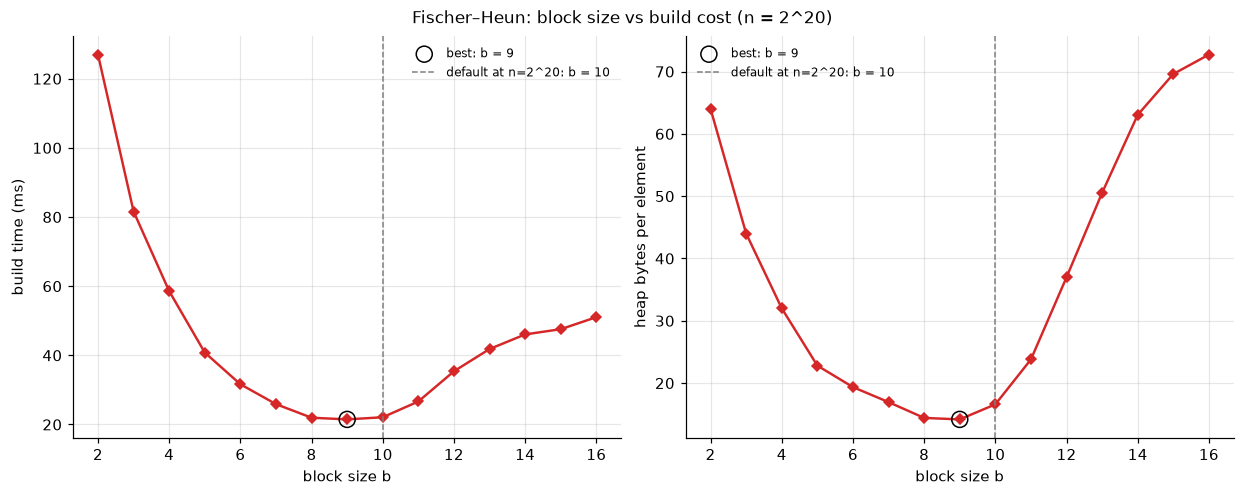

Fastest build at b = 9 | smallest structure at b = 9


In [17]:
fb = sub("FH_Different_Block_Sizes").sort_values("b")
if fb.empty:
    print("No block-size data.")
else:
    ncols = 2 if HAS_MEM else 1
    fig, axes = plt.subplots(1, ncols, figsize=(5.6 * ncols, 4.4), squeeze=False)
    panels = [("t", 1e-6, "build time (ms)")] + ([("bpe", 1.0, "heap bytes per element")] if HAS_MEM else [])
    for ax, (col, sc, ylab) in zip(axes[0], panels):
        ax.plot(fb["b"], fb[col] * sc, marker="D", ms=5, lw=1.6, color=style("Fischer_Heun")[1])
        best = fb.loc[fb[col].idxmin()]
        ax.scatter([best["b"]], [best[col] * sc], s=110, facecolors="none", edgecolors="k", zorder=3, label=f"best: b = {int(best['b'])}")
        ax.axvline(FH_DEFAULT_B, color="gray", ls="--", lw=1, label=f"default at n=2^20: b = {FH_DEFAULT_B}")
        ax.set_xlabel("block size b")
        ax.set_ylabel(ylab)
        ax.grid(True, alpha=0.3)
        ax.legend(frameon=False, fontsize=8)
    fig.suptitle("Fischer\u2013Heun: block size vs build cost (n = 2^20)", fontsize=11)
    save(fig, "F1_fh_block_size")
    print("Fastest build at b =", int(fb.loc[fb['t'].idxmin(), 'b']),
          "| smallest structure at b =", int(fb.loc[fb['bpe'].idxmin(), 'b']) if HAS_MEM else "n/a")

---
All figures were saved to `figure` (PNG for quick viewing, PDF for the report).